# Three Ways to Find Leading Indicators

A lagging indicator (for example, **D7 retention**) takes time to materialize, which makes an immediate
diagnosis hard. So we look for **leading indicators** that let us gauge the lagging indicator ahead of
time, and manage those alongside it.

This notebook takes **a single new-user event log** (`data/event_log.csv`) and searches for "the
leading indicators that will lift D7 retention of new users" using **three methods**. *Same data,
same target, three lenses.*

1. **EDA comparison** -- compare the D0~D1 behaviors of the retained and churned cohorts by share and average count
2. **SHAP values** -- build a model that predicts retention and decompose each behavior's contribution
3. **Sankey diagram** -- draw the behavior flow right after install and use color to see at which fork retention splits

## 2.5.1. Preparing the practice data

The cell below installs the dependencies. If the data is not there yet, run `python generate_data.py` in a terminal first to create `data/event_log.csv`.

This chapter has the heaviest dependencies of the book (lightgbm, shap, optuna, plotly, and so on),
so the first run can take a little longer because of installation time.

In [1]:
# Install dependencies (skips quickly if they are already installed)
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# --- Shared chart style for the book (unified palette, grid, spines) ---
PALETTE = ["#1f9d78", "#3b4556", "#d97706", "#6b7380"]  # green, slate, amber, muted
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3,
    "figure.dpi": 150, "legend.frameon": False,
})

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Open one in-memory DuckDB connection and reuse it throughout the notebook.
con = duckdb.connect()
con.execute(
    "CREATE OR REPLACE TABLE event_log AS "
    "SELECT * FROM read_csv_auto('data/event_log.csv')"
)
con.query(
    "SELECT COUNT(*) AS event_rows, COUNT(DISTINCT user_id) AS users FROM event_log"
).to_df()

,event_rows,users
0,136391,12000


### D7 retention labeling

With installed (D0) users as the population, a user is labeled **D7 retained (=1) if they have any activity on day 7 after install**.

First we register the install time and the D7 retention label as views. All three practice sections use the same label, so we define it only once.

When you work with a real log, users whose 7 days since install have not yet passed must be excluded
from the population. The labeling query in this practice treats anyone with no D7 activity as churned,
so if recent installs whose observation window has not ended are included, the results will be skewed.
All three practice sections use this view, so it is defined here once.


In [3]:
con.execute("""
-- Install (D0) time: each user's first system_app_install
CREATE OR REPLACE VIEW installs AS
  SELECT user_id, MIN(event_timestamp) AS install_ts, MIN(event_date) AS install_date
  FROM event_log WHERE event_name = 'system_app_install' GROUP BY 1;

-- D7 retention label: 1 if there is any activity on day 7 after install. 2.5.2~2.5.4 all use this view
CREATE OR REPLACE VIEW d7_label AS
  SELECT i.user_id, i.install_ts, i.install_date,
         MAX(CASE WHEN date_diff('day', i.install_date, e.event_date) = 7 THEN 1 ELSE 0 END) AS d7_retention_flag
  FROM installs AS i LEFT JOIN event_log AS e ON i.user_id = e.user_id
  GROUP BY 1, 2, 3
""")
labels = con.query("SELECT * FROM d7_label").to_df()
(labels["d7_retention_flag"].value_counts(normalize=True)
    .rename(index={0: "churned (0)", 1: "retained (1)"}).mul(100).round(1).rename("share(%)").to_frame())

,share(%)
d7_retention_flag,
churned (0),60.30
retained (1),39.70


---
## 2.5.2. Finding leading-indicator candidates with EDA

The first thing to do is **explore**. Without a predetermined hypothesis, lay out every event and look at
**what retained users do differently** from churned users. It is not clear-cut causation, but the behavioral
differences between the two cohorts give us leading-indicator candidates.

### Aggregating D0~D1 behaviors -- cohort comparison

On top of the label we attached in the setup section, we aggregate **D0~D1** behaviors per event and compare the two cohorts.
- `share` : the share of users who performed the behavior at least once (% within the cohort)
- `avg_event_count` : the average number of occurrences among users who performed it

Sorting by `share_diff` (retained minus churned) in descending order brings the behaviors that retained users
**do noticeably more** to the top. (The query is also in `sql/eda_leading_indicator.sql`.)

On top of this label, we aggregate D0~D1 behaviors per cohort and put each behavior's share and average count side by side.

In [4]:
eda_query = """
WITH log_data AS (   -- aggregate the raw log into counts per (user, event, screen, date)
    SELECT event_date, event_name, screen_name, user_id,
           SUM(event_count) AS event_count, MAX(description) AS description
    FROM event_log
    GROUP BY 1, 2, 3, 4
),
event_stat AS (      -- D0~D1 behaviors per cohort (retained / churned): users who did it and their average count
    SELECT r.d7_retention_flag, l.event_name, l.screen_name,
           COUNT(DISTINCT r.user_id) AS user_cnt, AVG(l.event_count) AS avg_event_count
    FROM d7_label AS r
    LEFT JOIN log_data AS l
      ON r.user_id = l.user_id AND l.event_date >= r.install_date
     AND date_diff('day', r.install_date, l.event_date) <= 1
    GROUP BY 1, 2, 3
),
population AS (SELECT d7_retention_flag, COUNT(*) AS total_user_cnt FROM d7_label GROUP BY 1),
cohort_info AS (     -- share (%) of users within the cohort who performed that behavior
    SELECT e.*, (e.user_cnt * 1.0 / p.total_user_cnt) * 100 AS share
    FROM event_stat AS e LEFT JOIN population AS p USING (d7_retention_flag)
)
SELECT event_name, screen_name,
       MAX(CASE WHEN d7_retention_flag = 0 THEN share           END) AS d7_ret0_share,
       MAX(CASE WHEN d7_retention_flag = 0 THEN avg_event_count END) AS d7_ret0_avg_cnt,
       MAX(CASE WHEN d7_retention_flag = 1 THEN share           END) AS d7_ret1_share,
       MAX(CASE WHEN d7_retention_flag = 1 THEN avg_event_count END) AS d7_ret1_avg_cnt,
       d7_ret1_share - d7_ret0_share     AS share_diff,
       d7_ret1_avg_cnt - d7_ret0_avg_cnt AS event_cnt_diff
FROM cohort_info
WHERE event_name IS NOT NULL
GROUP BY 1, 2
HAVING d7_ret1_share >= 10 OR d7_ret0_share >= 10
ORDER BY share_diff DESC
"""
eda = con.query(eda_query).to_df()
eda.round(1)

,event_name,screen_name,d7_ret0_share,d7_ret0_avg_cnt,d7_ret1_share,d7_ret1_avg_cnt,share_diff,event_cnt_diff
0,tap_like_button,content_detail,28.10,1.50,74.90,2.30,46.80,0.80
1,page_view_content_detail,content_detail,58.80,3.80,100.00,4.80,41.20,0.90
2,tap_share_button,content_detail,16.80,1.20,51.10,1.60,34.30,0.40
3,tap_tutorial_complete,onboarding,46.00,1.00,77.80,1.00,31.70,0.00
4,tap_search_button,search,6.70,3.70,30.60,5.70,23.90,1.90
5,system_push_permission_granted,permission,41.10,1.00,62.90,1.00,21.90,0.00
6,page_view_home,home,100.00,1.00,100.00,1.00,0.00,0.00
7,page_view_onboarding_step,onboarding,100.00,1.00,100.00,1.00,0.00,0.00
8,system_app_install,app,100.00,1.00,100.00,1.00,0.00,0.00
9,page_view_profile,profile,27.40,1.00,5.80,1.00,-21.50,0.00


### Interpretation and visualization

The table alone tells a story. Retained users **complete the tutorial, view content, and tap like** at a much
higher rate. Conversely, the share of **error popups and profile/settings** visits is higher on the churned
side. Putting the retained vs churned shares side by side in a bar chart makes the gap obvious at a glance.

Moving the table into a chart makes the differences jump out. Figure 2.1 in section 2.2 of the book is the output of this code.

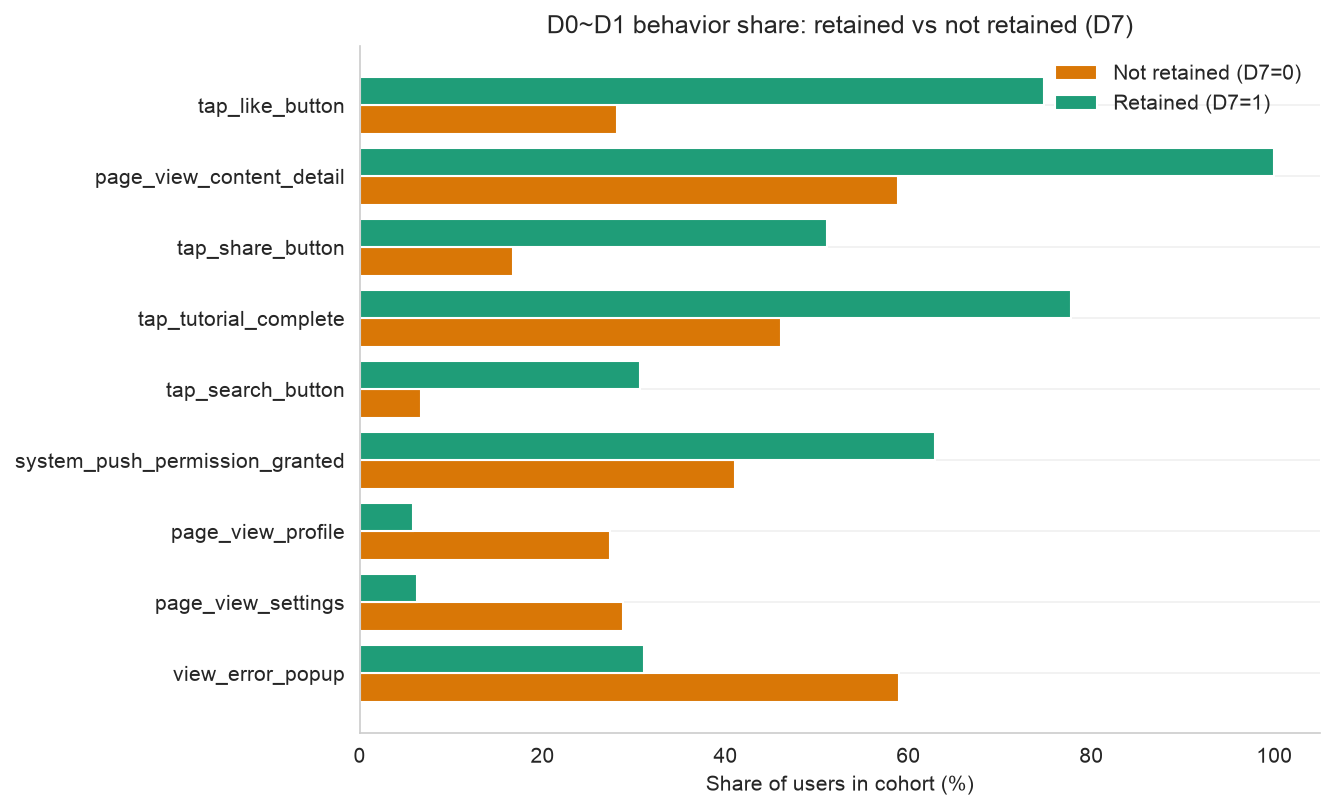

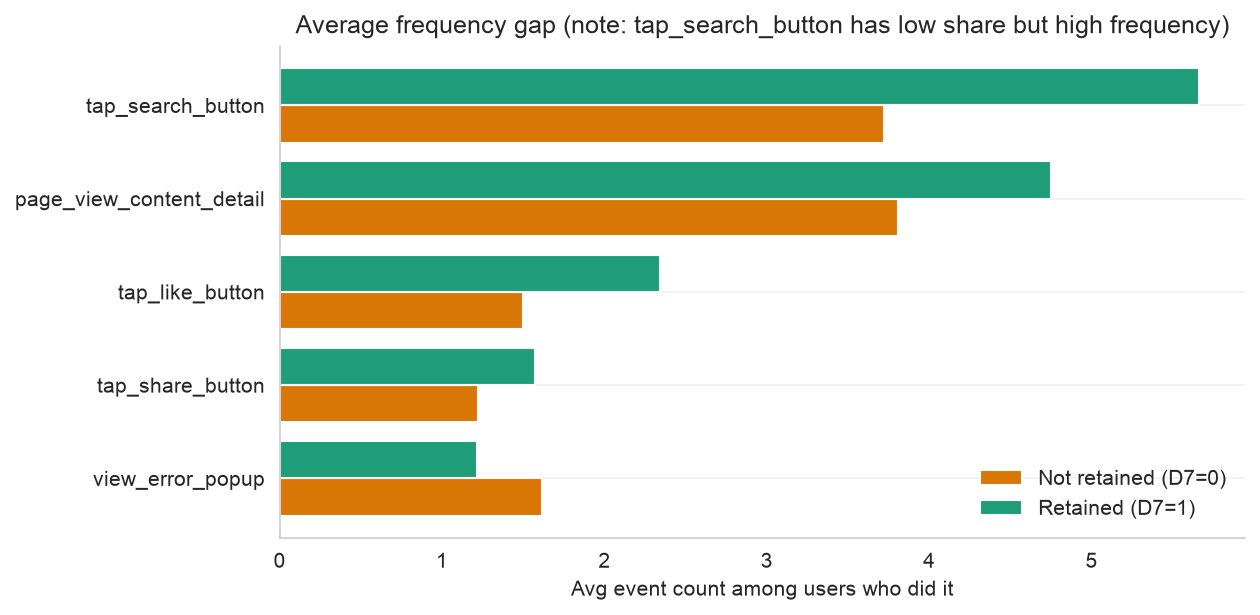

In [5]:
def gap_chart(frame, col0, col1, xlabel, title, figsize):
    # Horizontal bars comparing the retained (green) vs not-retained (amber) cohorts per behavior
    y = np.arange(len(frame))
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(y - 0.2, frame[col0], height=0.4, label="Not retained (D7=0)", color="#d97706")
    ax.barh(y + 0.2, frame[col1], height=0.4, label="Retained (D7=1)", color="#1f9d78")
    ax.set_yticks(y); ax.set_yticklabels(frame["event_name"])
    ax.set_xlabel(xlabel); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.show()

# (1) The 9 behaviors with the largest share gap
top9 = (eda.assign(abs_diff=eda["share_diff"].abs())
           .sort_values("abs_diff", ascending=False).head(9).sort_values("share_diff"))
gap_chart(top9, "d7_ret0_share", "d7_ret1_share", "Share of users in cohort (%)",
          "D0~D1 behavior share: retained vs not retained (D7)", (9, 5.5))

# (2) Average-count gap -- tap_search_button has a low share, but users who search do it often
spot = eda[eda["event_name"].isin(["page_view_content_detail", "tap_like_button", "tap_search_button",
                                   "tap_share_button", "view_error_popup"])].sort_values("d7_ret1_avg_cnt")
gap_chart(spot, "d7_ret0_avg_cnt", "d7_ret1_avg_cnt", "Avg event count among users who did it",
          "Average frequency gap (note: tap_search_button has low share but high frequency)", (8.5, 4.2))

`tap_search_button` (search) is a different kind of signal. Its **share** is low, but users who do search do it
**several times** -- that is, the average count (`avg_event_count`) is far higher among retained users.
It is a leading-indicator candidate that is easy to miss if you only look at share, and that shows up through count.

The query structure itself is not hard. Once you understand it, you can vary its parts to explore more widely.
For example, you could set the label to D1 retention instead of D7 and compare D0 behaviors only, or swap retention
for purchase conversion and compare the behaviors of users who entered the service.

---
## 2.5.3. Decomposing contributions with SHAP values

EDA handed us candidates; now it is time to **put several behaviors together at once** and quantify how much,
and in which direction, each one contributes to the retention prediction. We build an **LGBM** model that
predicts D7 retention and decompose the contributions with **SHAP values**. The goal is not to push the model's
accuracy as high as possible; the model is a tool for reading "which behaviors push the prediction up".

### 2.5.3.1. Preparing the feature matrix and labels

We aggregate the behaviors of the first (D0) install session into per-user features and attach D7 retention as the label.
(The query is also in `sql/feature_matrix.sql`.)

There is a reason the feature window is cut to the install-day (D0) session only. If behavior that happens after
the D7 retention label is mixed into the features, the model effectively "sees the future" when it predicts.
Once that kind of data leakage creeps in, none of the results can be trusted.

In [6]:
fm_query = """
WITH d0_session AS (   -- install-day (D0) session events only. Mixing in D1+ behavior leaks future information
    SELECT e.user_id, e.event_name, e.event_count, e.event_timestamp
    FROM installs AS i
    JOIN event_log AS e ON i.user_id = e.user_id AND date_diff('day', i.install_date, e.event_date) = 0
),
feat AS (
    SELECT user_id,
           MAX(CASE WHEN event_name = 'tap_tutorial_complete' THEN 1 ELSE 0 END) AS tap_tutorial_complete,
           MAX(CASE WHEN event_name = 'system_push_permission_granted'        THEN 1 ELSE 0 END) AS system_push_permission_granted,
           COUNT(*) FILTER (WHERE event_name = 'page_view_content_detail')      AS page_view_content_detail,
           COUNT(*) FILTER (WHERE event_name = 'tap_like_button')      AS tap_like_button,
           COUNT(*) FILTER (WHERE event_name = 'tap_search_button')       AS tap_search_button,
           COUNT(*) FILTER (WHERE event_name = 'tap_share_button')     AS tap_share_button,
           COUNT(*) FILTER (WHERE event_name = 'page_view_profile') AS page_view_profile,
           COUNT(*) FILTER (WHERE event_name = 'page_view_settings')     AS page_view_settings,
           COUNT(*) FILTER (WHERE event_name = 'view_error_popup')       AS view_error_popup,
           -- install-session length (seconds): first event to last event
           date_diff('second', MIN(event_timestamp), MAX(event_timestamp)) AS session_duration_sec
    FROM d0_session
    GROUP BY 1
)
SELECT l.d7_retention_flag, f.*
FROM d7_label AS l JOIN feat AS f USING (user_id)
ORDER BY user_id   -- fix the row order so the train/test split (and therefore accuracy) is the same on every run
"""
fm = con.query(fm_query).to_df()
y = fm["d7_retention_flag"]
X = fm.drop(columns=["d7_retention_flag", "user_id"])   # drop the identifier and the label from the features

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=314, stratify=y)
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tap_tutorial_complete,"12,000.00",0.59,0.49,0.00,0.00,1.00,1.00,1.00
system_push_permission_granted,"12,000.00",0.50,0.50,0.00,0.00,0.00,1.00,1.00
page_view_content_detail,"12,000.00",1.59,1.70,0.00,0.00,1.00,3.00,8.00
tap_like_button,"12,000.00",0.95,1.34,0.00,0.00,0.00,2.00,8.00
tap_search_button,"12,000.00",0.56,1.44,0.00,0.00,0.00,0.00,6.00
tap_share_button,"12,000.00",0.44,0.79,0.00,0.00,0.00,1.00,6.00
page_view_profile,"12,000.00",0.19,0.39,0.00,0.00,0.00,0.00,1.00
page_view_settings,"12,000.00",0.20,0.40,0.00,0.00,0.00,0.00,1.00
view_error_popup,"12,000.00",0.73,0.91,0.00,0.00,0.00,1.00,3.00
session_duration_sec,"12,000.00",119.36,82.55,9.00,56.00,99.00,162.00,541.00


### 2.5.3.2. Training and evaluating a baseline LGBM

First we train a reference model with fixed hyperparameters. Training stops when the validation AUC has not
improved for 10 rounds (early stopping). Class imbalance is corrected with `class_weight='balanced'`.

Once training is done we check the confusion matrix. Table 2.2 in section 2.3.3 of the book comes from here.

In [7]:
import lightgbm as lgb
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             confusion_matrix, classification_report)

baseline = lgb.LGBMClassifier(
    num_leaves=15, max_depth=-1, n_estimators=1000, learning_rate=0.01,
    colsample_bytree=0.9, subsample=0.9, subsample_freq=1,
    class_weight="balanced", random_state=314, n_jobs=4, metric="None", verbose=-1,
)
baseline.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)], eval_metric="auc",
    callbacks=[lgb.early_stopping(10, verbose=False)],
)

def report(model, tag):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba > 0.5).astype(int)
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, proba)
    print(f"[{tag}]  accuracy={acc:.4f}  AUC={auc:.4f}  best_iter={model.best_iteration_}")
    return acc, auc

base_acc, base_auc = report(baseline, "baseline")

/Users/delightroom/Desktop/data_analysis_101_en/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[baseline]  accuracy=0.7717  AUC=0.8534  best_iter=202


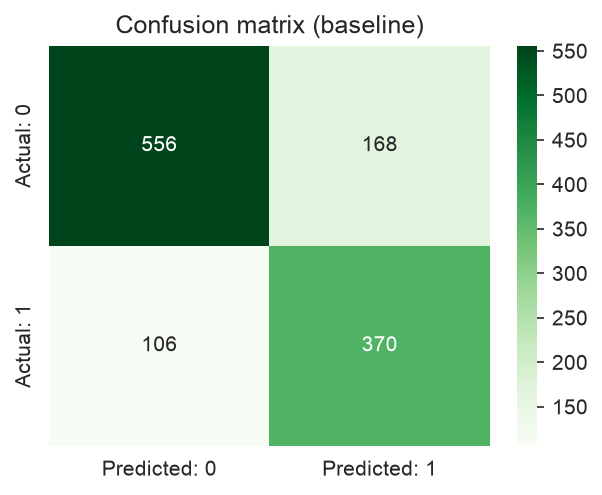

              precision    recall  f1-score   support

           0      0.840     0.768     0.802       724
           1      0.688     0.777     0.730       476

    accuracy                          0.772      1200
   macro avg      0.764     0.773     0.766      1200
weighted avg      0.780     0.772     0.774      1200



In [8]:
# Confusion matrix (rows = actual, columns = predicted) -- the source of Table 2.2 in section 2.3.3
proba = baseline.predict_proba(X_test)[:, 1]
pred = (proba > 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm, index=["Actual: 0", "Actual: 1"], columns=["Predicted: 0", "Predicted: 1"])
plt.figure(figsize=(4.2, 3.4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion matrix (baseline)")
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, digits=3))

### 2.5.3.3. (Optional) Hyperparameter optimization with Optuna

Since this is a model for interpretation, elaborate tuning is not strictly necessary, but you can use **Optuna**
to search the hyperparameters more deeply with cross-validated AUC as the objective. The sampler seed is fixed
for reproducibility, and the number of trials (`n_trials`) is kept small for the practice.

The model retrained with the best parameters found (clf) is compared against the baseline. The SHAP interpretation
that follows uses this model. If you skip this step, just run the single line `clf = baseline` in the SHAP
computation of the next section to pass the baseline model through as-is.

In [9]:
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold, cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        num_leaves=trial.suggest_int("num_leaves", 8, 64),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        n_estimators=300,
        min_child_samples=trial.suggest_int("min_child_samples", 10, 120),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        subsample_freq=1,
        class_weight="balanced", random_state=314, n_jobs=4, verbose=-1,
    )
    model = lgb.LGBMClassifier(**params)
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=314)
    return cross_val_score(model, X_train, y_train, cv=skf, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=314))
study.optimize(objective, n_trials=25, show_progress_bar=False)
print(f"best CV AUC = {study.best_value:.4f}")
study.best_params

best CV AUC = 0.8587


{'num_leaves': 8,
 'learning_rate': 0.014370958779904738,
 'min_child_samples': 112,
 'colsample_bytree': 0.8646419892459065,
 'subsample': 0.7357595345144871}

In [10]:
# Retrain with the best parameters and compare against the baseline -- this clf is used for the SHAP interpretation
best_params = {**study.best_params, "n_estimators": 1000, "subsample_freq": 1,
               "class_weight": "balanced", "random_state": 314, "n_jobs": 4,
               "metric": "None", "verbose": -1}
clf = lgb.LGBMClassifier(**best_params)
clf.fit(X_train, y_train, eval_set=[(X_test, y_test)], eval_metric="auc",
        callbacks=[lgb.early_stopping(10, verbose=False)])
tuned_acc, tuned_auc = report(clf, "optuna-tuned")

pd.DataFrame({"accuracy": [base_acc, tuned_acc], "AUC": [base_auc, tuned_auc]},
             index=["baseline", "optuna-tuned"]).round(4)

[optuna-tuned]  accuracy=0.7650  AUC=0.8425  best_iter=10


/Users/delightroom/Desktop/data_analysis_101_en/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,accuracy,AUC
baseline,0.77,0.85
optuna-tuned,0.77,0.84


For a model used for interpretation, a 1~2% difference in accuracy rarely changes the conclusion. Tuning
means little more than "read the contributions from a slightly better model", and now we draw the SHAP plots with this model.

### 2.5.3.4. SHAP summary plot & dependence plots

A SHAP summary plot packs a lot into one figure.
- **Horizontal axis (SHAP value)** : further right means that behavior **pushes the retention prediction up**
- **Color** : the magnitude of that feature's value (red = high, blue = low)

For example, if `page_view_content_detail` clusters on the right (retention up) when it is red (many views),
you can read the relationship "the more content a user views, the higher their retention".

/Users/delightroom/Desktop/data_analysis_101_en/.venv/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


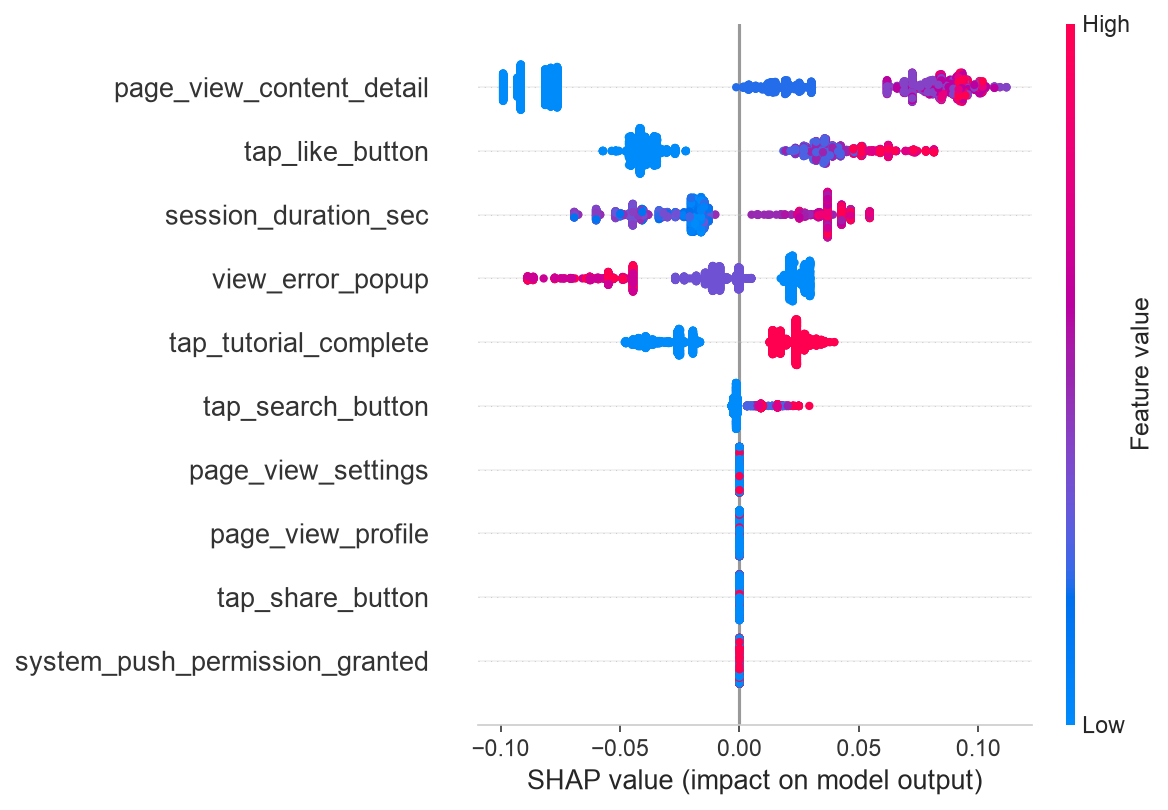

In [11]:
import shap
shap.initjs()

explainer = shap.TreeExplainer(clf.booster_)
X_shap = X_train.sample(frac=0.3, random_state=314)
shap_values = explainer.shap_values(X_shap)
# If binary classification returns a list, use the positive class
sv = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(sv, X_shap, show=True)

### SHAP dependence plot -- searching for thresholds (aha moments)

SHAP is computed per data row, so you can see **how the contribution changes with the feature value** as a curve.
If you see a **threshold where the contribution turns positive** as the value grows, that is an "aha moment"
candidate. (The color is the interaction with `page_view_content_detail`.)

Next, the dependence plots show how the contribution changes with the feature value and whether there is a threshold.

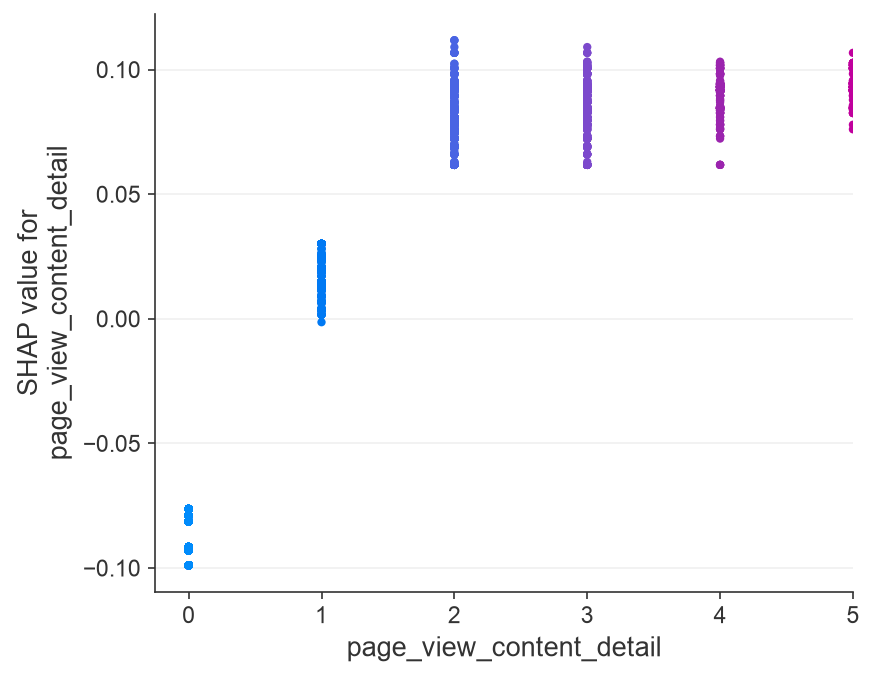

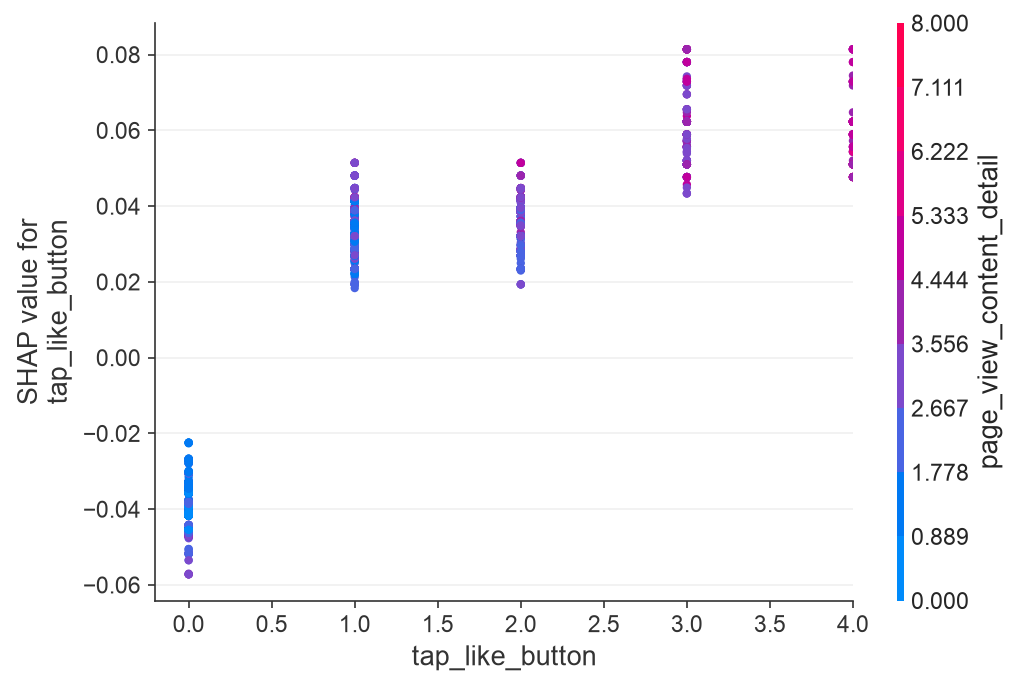

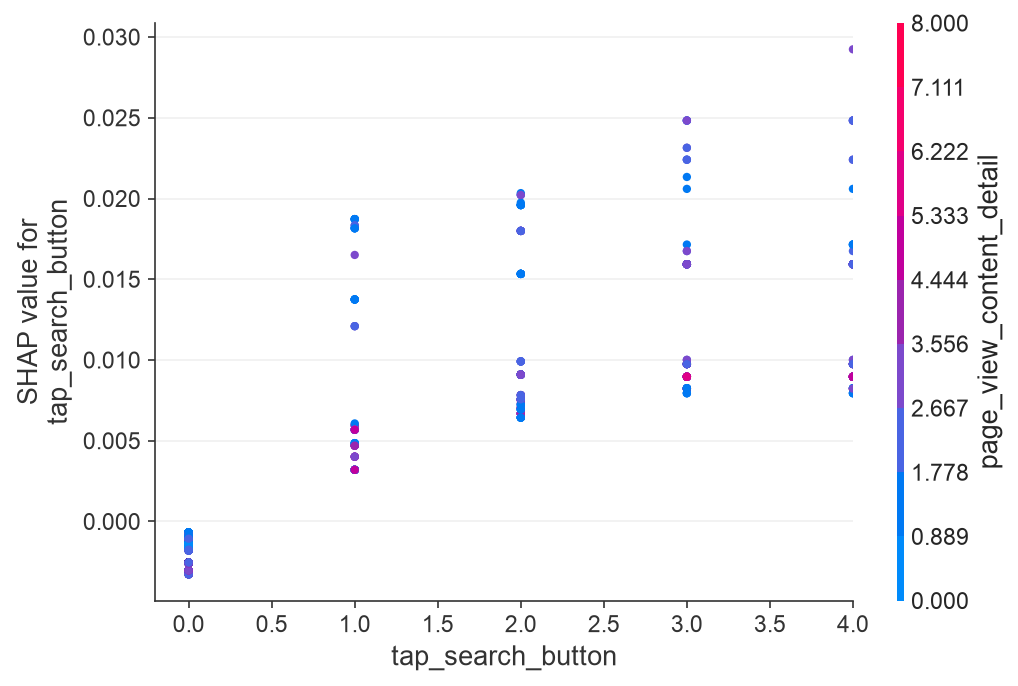

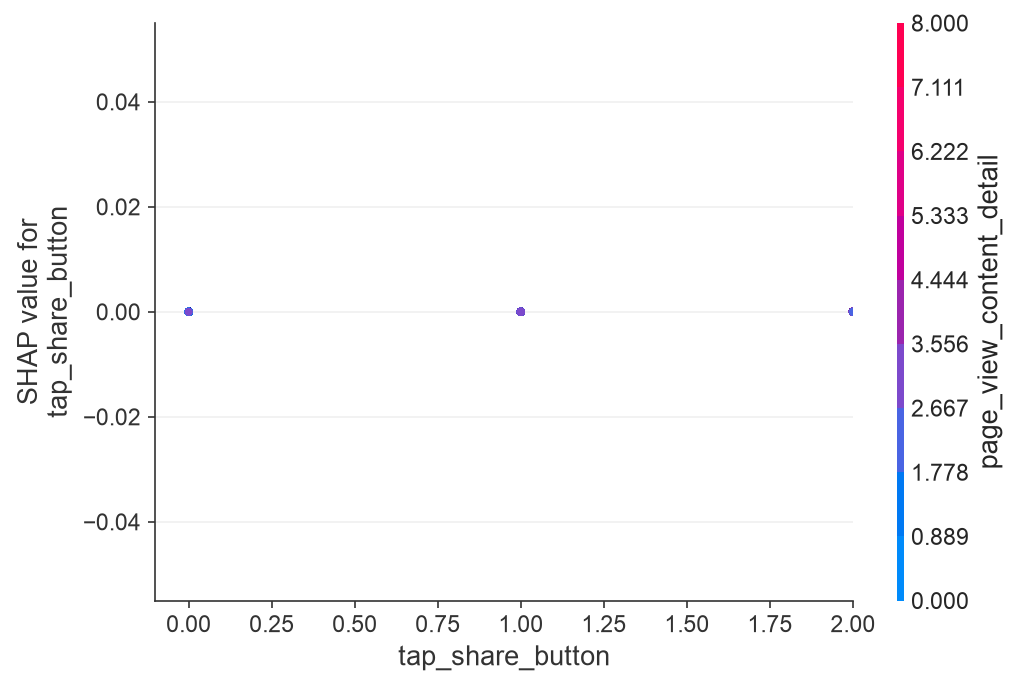

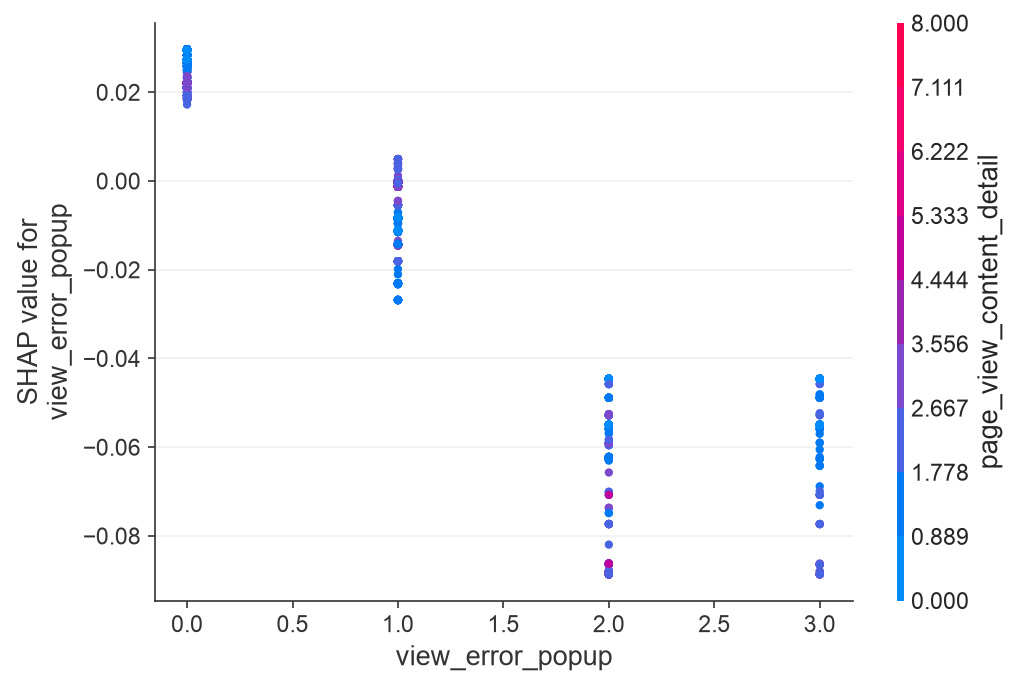

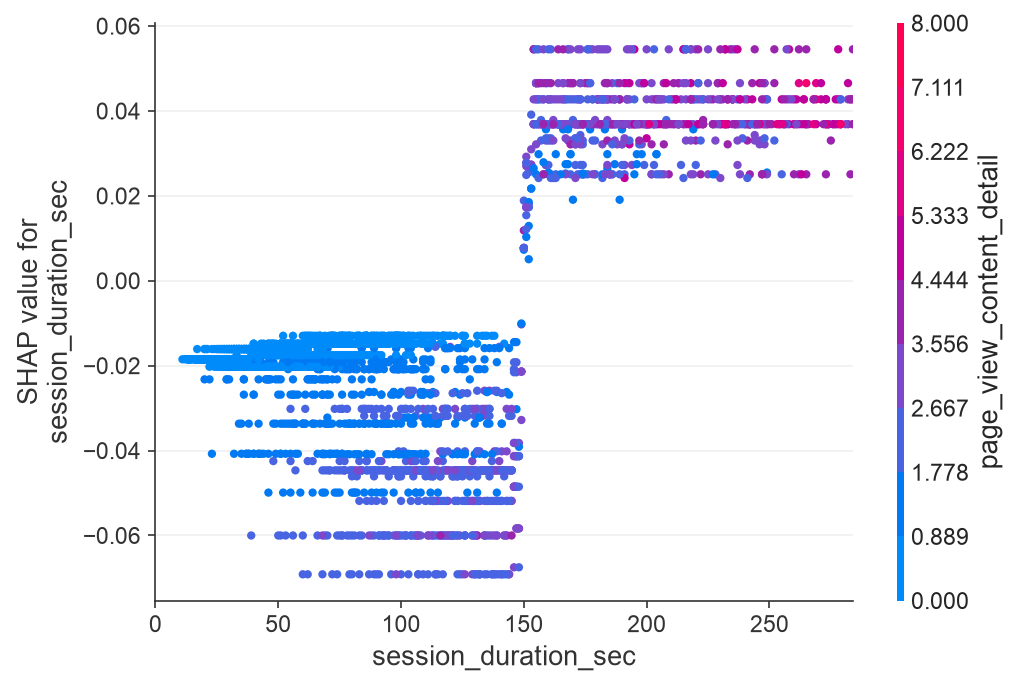

In [12]:
NUMERIC = ["page_view_content_detail", "tap_like_button", "tap_search_button",
           "tap_share_button", "view_error_popup", "session_duration_sec"]

for name in NUMERIC:
    xmax = X_shap[name].quantile(0.95) or max(X_shap[name].max(), 1)   # clip the top 5% extreme values from view
    shap.dependence_plot(name, sv, X_shap, interaction_index="page_view_content_detail",
                         xmin=0, xmax=xmax, show=True)

You can see the SHAP value turn positive around **150 seconds** for `session_duration_sec` and around
**3 taps** for `tap_like_button`. This lets you turn a vague behavior into a **concrete leading-indicator target**
to propose, such as "first session of 2 minutes 30 seconds or longer / 3 or more likes".

---
## 2.5.4. Diagnosing user flows with a Sankey diagram

So far we have looked at behaviors as **individual events**. The last lens is **flow**. We chain the screens
and actions a user passes through right after install in order, and **color each transition by the D7
retention rate** of the users who went through it. Then *which direction at the same fork lowers retention*
shows up in color. Figures 2.7 and 2.8 in section 2.4 of the book are the output of this practice.

### 2.5.4.1. Step transition query

We line up the events within 1 hour of install in order (removing consecutive duplicates), build step N -> N+1
transitions, and aggregate the user count and D7 retention rate per transition. At each step position only the
top `TOP_K` events are kept and the rest are lumped into `ETC` to keep the figure readable. (The query is also in
`sql/sankey_transitions.sql`.)

First we create a view that orders the events within 1 hour of install into per-user steps.

In [13]:
MAX_STEPS = 10    # first N events per user
TOP_K     = 6     # top K events per step (the rest become ETC)
MIN_USERS = 20    # minimum number of users for a link to be drawn

con.execute(f"""
-- Events within 1 hour of install, in order (consecutive duplicates removed) -> step number per user
CREATE OR REPLACE VIEW user_steps AS
  WITH session_events AS (
    SELECT i.user_id, e.event_name, e.event_timestamp,
           LAG(e.event_name) OVER (PARTITION BY i.user_id ORDER BY e.event_timestamp) AS prev_event
    FROM installs AS i
    JOIN event_log AS e
      ON i.user_id = e.user_id
     AND e.event_timestamp >= i.install_ts
     AND e.event_timestamp <= i.install_ts + INTERVAL 1 HOUR
  )
  SELECT user_id, event_name, event_timestamp,
         ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY event_timestamp) AS step_num
  FROM session_events
  WHERE prev_event IS NULL OR event_name != prev_event
  QUALIFY step_num <= {MAX_STEPS}
""")

At each step we keep only the top TOP_K events and lump the rest into ETC, then aggregate the user count and D7 retention rate per transition.

In [14]:
sankey_query = f"""
WITH event_volume AS (   -- rank events by frequency at each step
    SELECT step_num, event_name, COUNT(DISTINCT user_id) AS user_cnt,
           ROW_NUMBER() OVER (PARTITION BY step_num ORDER BY COUNT(DISTINCT user_id) DESC) AS rnk
    FROM user_steps
    GROUP BY 1, 2
),
steps_resolved AS (     -- lump events outside the top K into ETC
    SELECT s.user_id, s.step_num,
           CASE WHEN v.rnk <= {TOP_K} THEN s.event_name ELSE 'ETC' END AS event_name
    FROM user_steps AS s JOIN event_volume AS v USING (step_num, event_name)
),
transitions AS (        -- step N -> N+1 transitions
    SELECT a.user_id, a.step_num AS from_step,
           CAST(a.step_num AS VARCHAR) || '-' || a.event_name AS source,
           CAST(b.step_num AS VARCHAR) || '-' || b.event_name AS target
    FROM steps_resolved AS a
    JOIN steps_resolved AS b ON a.user_id = b.user_id AND b.step_num = a.step_num + 1
)
SELECT t.from_step, t.source, t.target,
       COUNT(DISTINCT t.user_id) AS user_count,
       COUNT(DISTINCT CASE WHEN r.d7_retention_flag = 1 THEN t.user_id END) * 100.0
         / NULLIF(COUNT(DISTINCT t.user_id), 0) AS d7_retention
FROM transitions AS t LEFT JOIN d7_label AS r USING (user_id)
GROUP BY 1, 2, 3
HAVING COUNT(DISTINCT t.user_id) >= {MIN_USERS}
ORDER BY from_step, user_count DESC
"""
flows = con.query(sankey_query).to_df()
print(f"transitions: {flows.shape[0]} rows | "
      f"D7 retention range: {flows['d7_retention'].min():.1f}% ~ {flows['d7_retention'].max():.1f}%")
flows.head(12)

transitions: 84 rows | D7 retention range: 2.6% ~ 86.7%


,from_step,source,target,user_count,d7_retention
0,1,1-system_app_install,2-page_view_onboarding_step,12000,39.67
1,2,2-page_view_onboarding_step,3-tap_tutorial_complete,7034,52.63
2,2,2-page_view_onboarding_step,3-page_view_home,2809,14.95
3,2,2-page_view_onboarding_step,3-system_push_permission_granted,2157,29.62
4,3,3-tap_tutorial_complete,4-system_push_permission_granted,3813,61.84
5,3,3-tap_tutorial_complete,4-page_view_home,3221,41.73
6,3,3-system_push_permission_granted,4-page_view_home,2157,29.62
7,3,3-page_view_home,4-page_view_content_detail,1196,27.59
8,3,3-page_view_home,4-page_view_settings,834,5.52
9,3,3-page_view_home,4-page_view_profile,779,5.65


### 2.5.4.2. A Sankey colored by retention

Link **thickness = number of users**, link **color = D7 retention rate** (gray = low -> amber -> green = high).
Comparing the colors of the links that branch from the same node shows which branch drags retention down.
Node color is the user-count-weighted average retention of the incoming links.

In [15]:
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook_connected"   # load plotly.js from the CDN to keep the notebook file light

labels = list(pd.unique(flows[["source", "target"]].values.ravel()))
label_to_idx = {lab: i for i, lab in enumerate(labels)}
flows["source_idx"] = flows["source"].map(label_to_idx)
flows["target_idx"] = flows["target"].map(label_to_idx)

# Node retention = user-count-weighted average of incoming links (start nodes with no incoming links use outgoing links)
node_ret = {}
for lab in labels:
    inc = flows[flows["target"] == lab]
    use = inc if len(inc) else flows[flows["source"] == lab]
    node_ret[lab] = np.average(use["d7_retention"], weights=use["user_count"]) if len(use) else 0.0

# Retention -> color: bottom 10% gray, top 10% green, interpolated through amber in between (book palette)
ret_min, ret_max = flows["d7_retention"].quantile(0.1), flows["d7_retention"].quantile(0.9)
def ret_to_rgba(ret, alpha=0.55):
    t = np.clip((ret - ret_min) / max(ret_max - ret_min, 1), 0, 1)
    if t < 0.5:  # gray -> amber
        s = t * 2; r, g, b = 201 + s*16, 197 - s*78, 192 - s*186
    else:        # amber -> green
        s = (t - 0.5) * 2; r, g, b = 217 - s*186, 119 + s*38, 6 + s*114
    return f"rgba({int(r)},{int(g)},{int(b)},{alpha})"

Draw the Sankey with the colored links and nodes.

In [16]:
link_colors = [ret_to_rgba(r) for r in flows["d7_retention"]]
node_colors = [ret_to_rgba(node_ret[l], 0.85) for l in labels]
node_disp = [f"{l}  ({node_ret[l]:.0f}%)" for l in labels]
link_hover = [f"{r.user_count:,} users | D7 retention: {r.d7_retention:.1f}%" for r in flows.itertuples()]

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(pad=28, thickness=20, line=dict(color="#333", width=0.6),
              label=node_disp, color=node_colors, hovertemplate="%{label}<extra></extra>"),
    link=dict(source=flows["source_idx"], target=flows["target_idx"],
              value=flows["user_count"], color=link_colors, customdata=link_hover,
              hovertemplate="%{source.label} → %{target.label}<br>%{customdata}<extra></extra>"),
))
fig.update_layout(title="Install-session flow → D7 retention (link color = retention rate)",
                  font=dict(size=12), width=1800, height=720, paper_bgcolor="white")
fig.show()

### Diagnosing the forks where retention splits

The colors already show it, but comparing the transitions that branch from the same starting point directly by retention rate makes it clearer.

We confirm the figure in numbers: among transitions branching from the same point, we pick the forks with the largest retention gap, plus the transitions with the highest and lowest retention.

In [17]:
# Transitions branching from the same point -- forks with the largest retention gap first
flows["ret_gap_at_source"] = flows.groupby("source")["d7_retention"].transform(lambda s: s.max() - s.min())
branches = (flows[flows["ret_gap_at_source"] > 15]
            .sort_values(["ret_gap_at_source", "source", "d7_retention"], ascending=[False, True, False]))
display(branches[["from_step", "source", "target", "user_count", "d7_retention"]].head(14).round(1))

# Highest and lowest retention transitions (50 or more users)
big = flows[flows["user_count"] >= 50]
for title, sub in [("TOP", big.nlargest(8, "d7_retention")), ("BOTTOM", big.nsmallest(8, "d7_retention"))]:
    print("=" * 70, f"\n{title} transitions by D7 retention (min 50 users)\n", "=" * 70)
    for r in sub.itertuples():
        print(f"  {r.source:>28s} -> {r.target:<26s}  {r.user_count:>5,}u  {r.d7_retention:5.1f}%")

,from_step,source,target,user_count,d7_retention
19,5,5-page_view_home,6-page_view_content_detail,2834,74.60
24,5,5-page_view_home,6-page_view_profile,475,24.80
23,5,5-page_view_home,6-page_view_settings,504,24.80
62,8,8-tap_like_button,9-page_view_content_detail,415,74.50
68,8,8-tap_like_button,9-tap_search_button,97,74.20
63,8,8-tap_like_button,9-tap_share_button,310,71.30
65,8,8-tap_like_button,9-view_error_popup,117,29.90
50,7,7-tap_like_button,8-tap_share_button,737,79.60
48,7,7-tap_like_button,8-page_view_content_detail,1258,78.70
57,7,7-tap_like_button,8-tap_search_button,103,72.80


TOP transitions by D7 retention (min 50 users)
             9-tap_like_button -> 10-page_view_content_detail    641u   86.7%
             9-tap_like_button -> 10-tap_share_button           428u   83.9%
    9-page_view_content_detail -> 10-tap_like_button            803u   83.6%
            8-tap_share_button -> 9-page_view_content_detail    677u   82.1%
            9-tap_share_button -> 10-page_view_content_detail    329u   80.9%
    8-page_view_content_detail -> 9-tap_like_button           1,450u   80.3%
             7-tap_like_button -> 8-tap_share_button            737u   79.6%
             7-tap_like_button -> 8-page_view_content_detail  1,258u   78.7%
BOTTOM transitions by D7 retention (min 50 users)
           4-page_view_profile -> 5-view_error_popup            547u    2.6%
          4-page_view_settings -> 5-view_error_popup            535u    3.6%
              3-page_view_home -> 4-page_view_settings          834u    5.5%
              3-page_view_home -> 4-page_view_profile 

---
## 2.5.5. The behaviors all three methods point to

Let's put the results of the three practice sections side by side.

| Method | Behaviors that rose to the top |
| --- | --- |
| EDA comparison (`share_diff`, `avg_event_count`) | tutorial completion, content detail views, likes, and (by count) search |
| SHAP (summary, dependence) | content detail views, error popups (negative contribution), session duration of about 150 seconds, about 3 likes |
| Sankey (`branches`) | the fork where users skip onboarding and go to home, the recovery via content detail views, the like -> content/share transitions |

Content detail views and likes were flagged by all three methods, tutorial completion by EDA and Sankey, and
session duration by SHAP alone. Put content detail views and 3 likes, which methods with different assumptions
jointly singled out, first in the experiment priority, and session duration, which came from only one method,
after that -- that is how to organize the hypothesis list. Keep in mind, though, that what we found here is only
correlation -- design an A/B test on the overlapping behaviors (chapter 3), and after the intervention, monitor
guardrail metrics alongside.
